### 1. Load the Processed EEG Dataset

Load the extracted EEG features from 15 motor imagery recordings across five subjects.

Separate numerical features, event labels, and subject identifiers. Subject IDs will be used for subject-independent cross-validation to avoid data leakage between training and test sets.

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/processed/eeg_features_all_subjects.csv")
dataset_df = pd.read_csv(data_path)

# Separate numerical features, labels, and metadata
metadata_columns = ["event", "subject_id", "recording_id"]

X = dataset_df.drop(columns=metadata_columns)
y = dataset_df["event"]
groups = dataset_df["subject_id"]

print("Feature matrix shape:", X.shape)
print("Number of subjects:", groups.nunique())

print("\nEvent distribution:")
print(y.value_counts().sort_index())

Feature matrix shape: (450, 21)
Number of subjects: 5

Event distribution:
event
T0    225
T1    113
T2    112
Name: count, dtype: int64


### 2. Binary Classification: T1 vs T2

The classification task focuses on distinguishing left-hand (T1) and right-hand (T2) motor imagery.

Rest epochs (T0) are excluded. Subject identifiers are preserved for group-based cross-validation.

In [2]:
binary_mask = y.isin(["T1", "T2"])

X_binary = X.loc[binary_mask].copy()
y_binary = y.loc[binary_mask].map({"T1": 0, "T2": 1})
groups_binary = groups.loc[binary_mask].copy()

print("Feature matrix shape:", X_binary.shape)
print("Number of subjects:", groups_binary.nunique())

print("\nClass distribution:")
print(y_binary.value_counts().sort_index())

Feature matrix shape: (225, 21)
Number of subjects: 5

Class distribution:
event
0    113
1    112
Name: count, dtype: int64


### 3. Cross-Validation Strategy

Leave-One-Subject-Out cross-validation is used to evaluate model generalization to unseen subjects.

In each fold, four subjects are used for training and the remaining subject for testing. This prevents EEG epochs from the same subject appearing in both sets.

In [3]:
from sklearn.model_selection import LeaveOneGroupOut

cv = LeaveOneGroupOut()
print("Number of folds:", cv.get_n_splits(groups=groups_binary))

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_binary, y_binary, groups=groups_binary), start=1):
    train_subjects = groups_binary.iloc[train_idx].unique()
    test_subjects = groups_binary.iloc[test_idx].unique()

    print(f"Fold {fold}: Train = {list(train_subjects)}, Test = {list(test_subjects)}")

Number of folds: 5
Fold 1: Train = ['S002', 'S003', 'S004', 'S005'], Test = ['S001']
Fold 2: Train = ['S001', 'S003', 'S004', 'S005'], Test = ['S002']
Fold 3: Train = ['S001', 'S002', 'S004', 'S005'], Test = ['S003']
Fold 4: Train = ['S001', 'S002', 'S003', 'S005'], Test = ['S004']
Fold 5: Train = ['S001', 'S002', 'S003', 'S004'], Test = ['S005']


### 4. Chance-Level Reference: DummyClassifier

A DummyClassifier is evaluated as a reference model that always predicts the most frequent training class.

This provides a simple benchmark for determining whether EEG-based classifiers perform better than trivial predictions under the same Leave-One-Subject-Out cross-validation.

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_scores = cross_validate(dummy_model, X_binary, y_binary, groups=groups_binary, cv=cv,
                              scoring=["accuracy", "balanced_accuracy", "f1_macro"])

dummy_results = pd.DataFrame({"Metric": ["Accuracy", "Balanced Accuracy", "Macro F1"],
                              "Mean": [dummy_scores["test_accuracy"].mean(),
                                       dummy_scores["test_balanced_accuracy"].mean(),
                                       dummy_scores["test_f1_macro"].mean()],
                              "Std": [dummy_scores["test_accuracy"].std(),
                                      dummy_scores["test_balanced_accuracy"].std(),
                                      dummy_scores["test_f1_macro"].std()]})
display(dummy_results.round(3))

,Metric,Mean,Std
0,Accuracy,0.502,0.018
1,Balanced Accuracy,0.500,0.000
2,Macro F1,0.334,0.008


### DummyClassifier Results

The DummyClassifier achieved a balanced accuracy of **0.500**, confirming chance-level discrimination between T1 and T2.

Accuracy was approximately 0.502, while Macro-F1 was substantially lower (0.334) because the model predicted only one class.

These results provide a reference for evaluating whether EEG-based classifiers learn meaningful patterns.

### 5. Logistic Regression Baseline

Logistic Regression is used as the initial baseline classifier.

StandardScaler is included in the pipeline to standardize features within each training fold, preventing data leakage. Performance is evaluated using Leave-One-Subject-Out cross-validation.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

baseline_model = make_pipeline(StandardScaler(),
                               LogisticRegression(max_iter=1000))
scoring = ["accuracy", "balanced_accuracy", "f1", "f1_macro"]

cv_results = cross_validate(baseline_model, X_binary, y_binary, groups=groups_binary, cv=cv, scoring=scoring)

baseline_scores = pd.DataFrame({metric: cv_results[f"test_{metric}"]
                                for metric in scoring})
display(baseline_scores.round(3))

print("\nMean cross-validation scores:")
display(baseline_scores.agg(["mean", "std"]).round(3))

,accuracy,balanced_accuracy,f1,f1_macro
0,0.600,0.601,0.609,0.600
1,0.556,0.551,0.444,0.537
2,0.511,0.515,0.577,0.499
3,0.600,0.609,0.710,0.533
4,0.356,0.345,0.453,0.335



Mean cross-validation scores:


,accuracy,balanced_accuracy,f1,f1_macro
mean,0.524,0.524,0.559,0.501
std,0.101,0.107,0.112,0.100


### Logistic Regression Results

Logistic Regression achieved a mean balanced accuracy of **0.524**, slightly above the DummyClassifier baseline (0.500).

Macro-F1 improved from 0.334 to 0.501, indicating better performance across both classes.

However, substantial variability between subjects suggests limited cross-subject generalization.

### 6. Model Comparison: Logistic Regression, LDA, SVM

Logistic Regression, Linear Discriminant Analysis (LDA), and Support Vector Machine (SVM) with an RBF kernel are compared using the same Leave-One-Subject-Out cross-validation strategy.

Feature scaling is performed within each training fold to prevent data leakage.

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC

models = {"Logistic Regression": baseline_model,
          "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
          "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf"))}
comparison_results = []

for model_name, model in models.items():
    cv_results = cross_validate(model, X_binary, y_binary, groups=groups_binary, cv=cv, scoring=scoring)

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]

        comparison_results.append({ "Model": model_name, 
                                    "Metric": metric,
                                    "Mean": scores.mean(),
                                    "Std": scores.std()})
comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,Model,Metric,Mean,Std
0,Logistic Regression,accuracy,0.524,0.091
1,Logistic Regression,balanced_accuracy,0.524,0.096
2,Logistic Regression,f1,0.559,0.100
3,Logistic Regression,f1_macro,0.501,0.089
4,LDA,accuracy,0.556,0.064
5,LDA,balanced_accuracy,0.558,0.064
6,LDA,f1,0.556,0.099
7,LDA,f1_macro,0.538,0.052
8,SVM (RBF),accuracy,0.502,0.041
9,SVM (RBF),balanced_accuracy,0.509,0.039


### Model Comparison Results

LDA achieved the highest balanced accuracy (**0.558**) and Macro-F1 (**0.538**) among the evaluated classifiers.

Logistic Regression showed slightly weaker performance, while SVM remained close to the DummyClassifier reference.

Although LDA performed best on average, its improvement over chance-level classification was modest, indicating limited cross-subject generalization.

### 7. LDA Error Analysis

Out-of-fold predictions are collected using Leave-One-Subject-Out cross-validation to examine classification errors on unseen subjects.

A confusion matrix and classification report are used to assess performance for left-hand (T1) and right-hand (T2) motor imagery.

In [7]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, classification_report

lda_model = models["LDA"]
y_true_all = []
y_pred_all = []
fold_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X_binary, y_binary, groups=groups_binary), start=1):
    X_train = X_binary.iloc[train_idx]
    X_test = X_binary.iloc[test_idx]
    y_train = y_binary.iloc[train_idx]
    y_test = y_binary.iloc[test_idx]

    model = clone(lda_model)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    y_true_all.extend(y_test.to_numpy())
    y_pred_all.extend(y_pred)

    fold_results.append({"Subject": groups_binary.iloc[test_idx].iloc[0],
                         "Test samples": len(y_test),
                         "Correct": int((y_test.to_numpy() == y_pred).sum()),
                         "Accuracy": (y_test.to_numpy() == y_pred).mean()})

display(pd.DataFrame(fold_results).round(3))
print("\nClassification report:")
print(classification_report(y_true_all, y_pred_all,
                            target_names=["T1 (Left)", "T2 (Right)"], zero_division=0))

print("\nConfusion matrix:")
cm = confusion_matrix(y_true_all, y_pred_all)
display(pd.DataFrame(cm, index=["Actual T1", "Actual T2"], columns=["Predicted T1", "Predicted T2"]))

,Subject,Test samples,Correct,Accuracy
0,S001,45,22,0.489
1,S002,45,28,0.622
2,S003,45,23,0.511
3,S004,45,29,0.644
4,S005,45,23,0.511



Classification report:
              precision    recall  f1-score   support

   T1 (Left)       0.56      0.51      0.54       113
  T2 (Right)       0.55      0.60      0.57       112

    accuracy                           0.56       225
   macro avg       0.56      0.56      0.55       225
weighted avg       0.56      0.56      0.55       225


Confusion matrix:


,Predicted T1,Predicted T2
Actual T1,58,55
Actual T2,45,67


### LDA Error Analysis

LDA correctly classified **125 of 225 epochs (55.6%)** using Leave-One-Subject-Out cross-validation.

Performance varied across subjects (48.9%–64.4%). The model identified right-hand imagery (T2) slightly better than left-hand imagery (T1), with recall values of 60% and 51%, respectively.

The substantial overlap in classification outcomes indicates that the current features provide limited discrimination between the two motor imagery classes across unseen subjects.

### 8. LDA Confusion Matrix Visualization

The confusion matrix visualizes correct and incorrect predictions for left-hand (T1) and right-hand (T2) motor imagery using out-of-fold predictions from Leave-One-Subject-Out cross-validation.

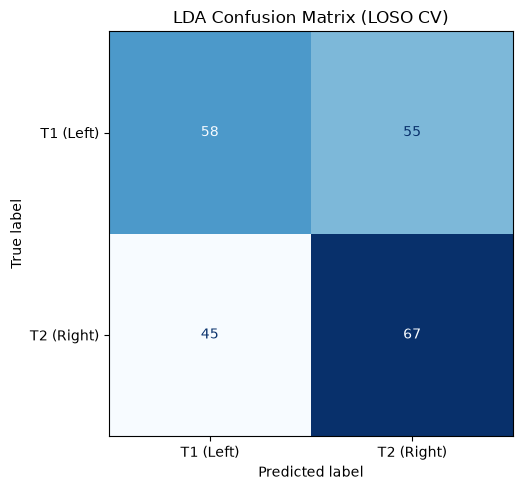

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["T1 (Left)", "T2 (Right)"])
fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("LDA Confusion Matrix (LOSO CV)")
plt.tight_layout()
plt.show()

LDA correctly classified 58 T1 epochs and 67 T2 epochs, while misclassifying 100 of 225 epochs overall. The model shows slightly better recall for T2, but substantial confusion remains between the two classes.

## Conclusion

Three baseline classifiers were evaluated using Leave-One-Subject-Out cross-validation across five subjects.

LDA achieved the best exploratory performance with a mean balanced accuracy of **0.558** and Macro-F1 of **0.538**, outperforming Logistic Regression, SVM, and the DummyClassifier reference.

However, performance remained only modestly above chance level, with noticeable differences between subjects.

**Next step:** Examine model performance on individual held-out subjects and analyze prediction errors.